# Low-GOR oils: pseudo-fractions, CCE and differential liberation

**Version 1.0.0 · companion to [NeqSim #4528](https://github.com/equinor/neqsim/issues/4528)**

[Open in Colab](https://colab.research.google.com/github/EvenSol/NeqSim-Colab/blob/master/notebooks/PVT/low_gor_oil_pseudofraction_paper_4528.ipynb)

Build a traceable live-oil model from the published Sadi-reservoir composition, compare
six-lump and recharacterized fluids, simulate closed-cell expansion and gas-removing
liberation, and separate calibration from hold-out comparison. All results below are
calculated with source-built NeqSim. They are **a reproducibility and capability study**;
they do not reproduce the authors' fully tuned PVTp model.

Primary source: F. J. Kadhim and N. J. Al-Ameri (2026), *Characterization of fluid properties
and pseudo-fraction analysis for oils with low gas oil ratios*, IJCPE 27(1), 105–115,
[DOI:10.31699/IJCPE.2026.1.9](https://doi.org/10.31699/IJCPE.2026.1.9).
[Open-access paper](https://ijcpe.uobaghdad.edu.iq/index.php/ijcpe/article/download/1406/1033/6948).
Numerical tables below are attributed transcriptions from Tables 1–3, licensed CC BY 4.0.

## 1. Runtime and provenance

A fresh Colab session installs Python dependencies and builds the pinned NeqSim master
revision audited for this study. Change `NEQSIM_SOURCE_REF` only when intentionally
refreshing the benchmark. Java 17 and Maven/wrapper access are required.

Local validation may reuse `NEQSIM_SOURCE_ROOT`, `NEQSIM_SOURCE_JAR` and an audited
`NEQSIM_AUDITED_SOURCE_MANIFEST`. The manifest path verifies source, POM and JAR hashes;
it is explicitly reported instead of pretending the reconstructed tree has Git metadata.
The saved execution uses the master-equivalent Java tree at 6b176739: the GitHub connector
comparison to 98d185de contains no `src` or `pom.xml` changes. Neither Python-package
Java nor an unverified JAR is used.

In [1]:
import hashlib
import importlib.util
import importlib.metadata
import json
import os
from pathlib import Path
import subprocess
import sys
import zipfile

packages = {
    "jpype": "JPype1==1.7.1",
    "numpy": "numpy==2.5.4",
    "pandas": "pandas==3.1.0",
    "matplotlib": "matplotlib==3.11.2",
    "scipy": "scipy==1.18.1",
}
missing = [
    package
    for module, package in packages.items()
    if importlib.util.find_spec(module) is None
    or importlib.metadata.version(package.split("==")[0]) != package.split("==")[1]
]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)

NEQSIM_SOURCE_REF = "98d185ded48c5c0c12b2faec374544b6b6b043b1"
source_root = Path(os.environ.get("NEQSIM_SOURCE_ROOT", "/content/neqsim-4528"))
manifest_path = os.environ.get("NEQSIM_AUDITED_SOURCE_MANIFEST")


def sha256_file(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


if manifest_path:
    manifest = json.loads(Path(manifest_path).read_text())
    source_files = [
        (item.relative_to(source_root).as_posix(), sha256_file(item))
        for item in sorted((source_root / "src/main").rglob("*"))
        if item.is_file()
    ]
    source_digest = hashlib.sha256(
        json.dumps(source_files, separators=(",", ":")).encode()
    ).hexdigest()
    assert source_digest == manifest["main_source_sha256"]
    assert sha256_file(source_root / "pom.xml") == manifest["pom_sha256"]
    assert manifest["upstream_commit"] == NEQSIM_SOURCE_REF
    source_jar = Path(manifest["jar"])
    assert sha256_file(source_jar) == manifest["jar_sha256"]
    provenance_mode = "AUDITED_MASTER_EQUIVALENT_SOURCE"
    source_commit = manifest["source_base_commit"]
else:
    if not (source_root / ".git").exists():
        subprocess.run(
            ["git", "clone", "https://github.com/equinor/neqsim.git", str(source_root)],
            check=True,
            capture_output=True,
            text=True,
        )
    subprocess.run(
        ["git", "fetch", "origin", NEQSIM_SOURCE_REF],
        cwd=source_root,
        check=True,
        capture_output=True,
        text=True,
    )
    subprocess.run(
        ["git", "checkout", "--detach", NEQSIM_SOURCE_REF],
        cwd=source_root,
        check=True,
        capture_output=True,
        text=True,
    )
    source_commit = subprocess.check_output(
        ["git", "rev-parse", "HEAD"], cwd=source_root, text=True
    ).strip()
    assert source_commit == NEQSIM_SOURCE_REF
    build = subprocess.run(
        ["bash", "./mvnw", "-q", "-DskipTests", "compile", "dependency:copy-dependencies"],
        cwd=source_root,
        capture_output=True,
        text=True,
    )
    if build.returncode:
        raise RuntimeError(build.stdout[-4000:] + build.stderr[-4000:])
    source_jar = source_root / "target/neqsim-notebook-runtime.jar"
    with zipfile.ZipFile(source_jar, "w", zipfile.ZIP_DEFLATED) as archive:
        classes = source_root / "target/classes"
        for item in sorted(classes.rglob("*")):
            if item.is_file():
                archive.write(item, item.relative_to(classes))
    provenance_mode = "PINNED_MASTER_GIT_BUILD"

os.environ["NEQSIM_JVM_AUTOSTART"] = "0"
import jpype

if jpype.isJVMStarted():
    raise RuntimeError("Restart the runtime before changing the NeqSim classpath.")
jpype.addClassPath(str(source_jar))
jpype.addClassPath(str(source_root / "target/dependency/*"))
jpype.startJVM(convertStrings=True)
JClass = jpype.JClass
probe = JClass("neqsim.pvtsimulation.regression.PVTRegression")
loaded_from = str(probe.class_.getProtectionDomain().getCodeSource().getLocation())
assert (
    Path(
        str(probe.class_.getProtectionDomain().getCodeSource().getLocation().toURI().getPath())
    ).resolve()
    == source_jar.resolve()
)
runtime = {
    "requested_master_commit": NEQSIM_SOURCE_REF,
    "source_base_commit": source_commit,
    "mode": provenance_mode,
    "jar_sha256": sha256_file(source_jar),
    "class_location": loaded_from,
    "python": sys.version.split()[0],
    "packages": {
        package.split("==")[0]: importlib.metadata.version(package.split("==")[0])
        for package in packages.values()
    },
    "java": str(JClass("java.lang.System").getProperty("java.version")),
}
print(json.dumps(runtime, indent=2))

{
  "requested_master_commit": "98d185ded48c5c0c12b2faec374544b6b6b043b1",
  "source_base_commit": "6b176739c91a25c03d42cf12066c036001b06357",
  "mode": "AUDITED_MASTER_EQUIVALENT_SOURCE",
  "jar_sha256": "e7fa319e5274e6f872becaf8ffcb05a4f8bf3c08e9c78bf36a694206f876133a",
  "class_location": "file:/workspace/scratch/a22e940bc35b/source/target/neqsim-source-baseline.jar",
  "python": "3.12.14",
  "packages": {
    "JPype1": "1.7.1",
    "numpy": "2.5.4",
    "pandas": "3.1.0",
    "matplotlib": "3.11.2",
    "scipy": "1.18.1"
  },
  "java": "17.0.20"
}


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import brentq

plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.grid": True})
PrEos = JClass("neqsim.thermo.system.SystemPrEos")
ThermoOps = JClass("neqsim.thermodynamicoperations.ThermodynamicOperations")
SaturationPressure = JClass("neqsim.pvtsimulation.simulation.SaturationPressure")
ConstantMassExpansion = JClass("neqsim.pvtsimulation.simulation.ConstantMassExpansion")
DifferentialLiberation = JClass("neqsim.pvtsimulation.simulation.DifferentialLiberation")
DoubleArray = jpype.JArray(jpype.JDouble)
PSI_TO_BAR = 0.06894757293168
ATM_PSI = 14.6959487755
TEMPERATURE_K = (190.4 - 32.0) * 5.0 / 9.0 + 273.15
PAPER_PB_BARA = 3078.0 * PSI_TO_BAR
checks = {}
print(f"Reservoir temperature: {TEMPERATURE_K:.3f} K / {TEMPERATURE_K - 273.15:.2f} °C")
print(f"Reported bubble pressure: {PAPER_PB_BARA:.6f} bara")

Reservoir temperature: 361.150 K / 88.00 °C
Reported bubble pressure: 212.220629 bara


## 2. Published inputs and data quality

Table 1 labels the amounts “mole fraction” but they sum to approximately 100: use **mol%**
and normalize once for rounding. Its `n-C4H12` is mapped to **n-butane (C4H10)**. Table 3
molecular weights are interpreted as g/mol, converted to kg/mol at the API boundary.
Specific gravity is dimensionless. Critical pressure is printed **psig**; our baseline
adds one atmosphere before converting to bara. An alternative “the heading meant psia”
interpretation is evaluated explicitly, never applied silently.

The paper's text gives 729.7 **g/m³**, but Figure 4 uses kg/m³. We interpret the single
density anchor as **729.7 kg/m³** and retain that correction as an uncertainty. The
text uses 190°F versus 190.4°F in Table 1 and mentions 3063 psi versus 3078 psia for
saturation: Table 1 defines this notebook's reference. Full numerical CCE/DL observations,
BIPs, volume shifts and the LBC calibration are not supplied as tables.

In [3]:
light = pd.DataFrame(
    {
        "component": [
            "nitrogen",
            "CO2",
            "methane",
            "ethane",
            "propane",
            "i-butane",
            "n-butane",
            "i-pentane",
            "n-pentane",
            "n-hexane",
        ],
        "mol_percent": [
            0.554617,
            0.174879,
            40.1193,
            8.95782,
            5.33932,
            0.907374,
            2.96795,
            1.50596,
            1.80975,
            3.27674,
        ],
    }
)
lumps = pd.DataFrame(
    [
        ["C7_C8", 6.32409, 128.525, 0.814123, 662.241, 411.152649, 0.33599],
        ["C9_C10", 5.49587, 160.328, 0.854311, 793.552, 336.2677, 0.443126],
        ["C11_C13", 6.36648, 199.123, 0.885867, 913.386, 275.898651, 0.562306],
        ["C14_C16", 4.68974, 245.122, 0.92026, 1051.68, 219.234085, 0.723786],
        ["C17_C20", 4.43536, 295.933, 0.946137, 1151.58, 188.849182, 0.850006],
        ["C21_C34", 7.07476, 399.862, 0.982621, 1280.58, 162.046417, 1.01161],
    ],
    columns=["component", "mol_percent", "MW_g_mol", "SG", "Tc_F", "Pc_psig", "omega"],
)
total_amount = light.mol_percent.sum() + lumps.mol_percent.sum()
plus_mw = np.average(lumps.MW_g_mol, weights=lumps.mol_percent) / 1000.0
plus_sg = (lumps.mol_percent * lumps.MW_g_mol).sum() / (
    lumps.mol_percent * lumps.MW_g_mol / lumps.SG
).sum()
print(f"Raw total: {total_amount:.9f} mol%; normalization factor: {100 / total_amount:.9f}")
print(f"C7+ sum: {lumps.mol_percent.sum():.6f} mol%")
print(f"Inferred C7+ MW: {plus_mw:.12f} kg/mol; SG: {plus_sg:.12f}")
display(light)
display(lumps)
checks["composition_rounding_under_1e-4_mol_percent"] = abs(total_amount - 100) < 1e-4
checks["C7_plus_lump_total"] = abs(lumps.mol_percent.sum() - 34.3863) < 1e-8

Raw total: 100.000010000 mol%; normalization factor: 0.999999900
C7+ sum: 34.386300 mol%
Inferred C7+ MW: 0.240000047459 kg/mol; SG: 0.919394476362


,component,mol_percent
0,nitrogen,0.554617
1,CO2,0.174879
2,methane,40.119300
3,ethane,8.957820
4,propane,5.339320
5,i-butane,0.907374
6,n-butane,2.967950
7,i-pentane,1.505960
8,n-pentane,1.809750
9,n-hexane,3.276740


,component,mol_percent,MW_g_mol,SG,Tc_F,Pc_psig,omega
0,C7_C8,6.32409,128.525,0.814123,662.241,411.152649,0.335990
1,C9_C10,5.49587,160.328,0.854311,793.552,336.267700,0.443126
2,C11_C13,6.36648,199.123,0.885867,913.386,275.898651,0.562306
3,C14_C16,4.68974,245.122,0.920260,1051.680,219.234085,0.723786
4,C17_C20,4.43536,295.933,0.946137,1151.580,188.849182,0.850006
5,C21_C34,7.07476,399.862,0.982621,1280.580,162.046417,1.011610


Table 2 sum as printed: 34.499678 mol%
Table 2 minus Table 1 C7+: +0.113378 mol%
Table 2 is retained for QC only: no invented per-SCN MW/SG or silent repair.


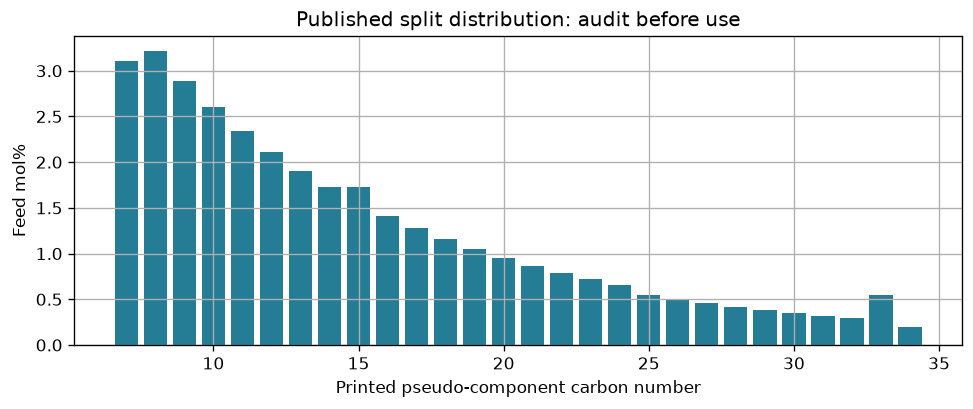

In [4]:
table2_amounts = np.array(
    [
        3.10686,
        3.21723,
        2.89267,
        2.60321,
        2.34483,
        2.11401,
        1.90763,
        1.72295,
        1.72295,
        1.40936,
        1.27623,
        1.15678,
        1.04944,
        0.952899,
        0.865994,
        0.787701,
        0.71711,
        0.653407,
        0.54375,
        0.496833,
        0.454245,
        0.415657,
        0.380665,
        0.348911,
        0.320066,
        0.293848,
        0.543875,
        0.200567,
    ]
)
print(f"Table 2 sum as printed: {table2_amounts.sum():.6f} mol%")
print(f"Table 2 minus Table 1 C7+: {table2_amounts.sum() - 34.3863:+.6f} mol%")
print("Table 2 is retained for QC only: no invented per-SCN MW/SG or silent repair.")
fig, ax = plt.subplots(figsize=(8, 3.3), layout="constrained")
ax.bar(np.arange(7, 35), table2_amounts, color="#247c95")
ax.set(
    xlabel="Printed pseudo-component carbon number",
    ylabel="Feed mol%",
    title="Published split distribution: audit before use",
)
plt.show()

## 3. Build a composable six-lump PR fluid

Use classic mixing and NeqSim's database BIPs, with volume correction enabled. Critical
properties and acentric factors of the six lumps are overwritten with Table 3 values in
each initialized phase. These are explicit **modelling choices**, not the undisclosed PVTp
settings. The saved base fluid can be cloned into process streams or another PVT experiment.

The paper also tunes individual Ωa and Ωb (Table 4). This baseline uses NeqSim defaults.
General PR exposes persistent Ωa but not Ωb; the specialized five-component BNS model is
not an arbitrary 16-component oil assay substitute. See [#4548](https://github.com/equinor/neqsim/issues/4548).
No partial Table 4 application is presented as the published tuned model.

In [5]:
def build_fluid(critical_pressure_basis="psig", tc_multiplier=1.0):
    fluid = PrEos(TEMPERATURE_K, 350.0)
    for row in light.itertuples(index=False):
        fluid.addComponent(row.component, float(row.mol_percent))
    for row in lumps.itertuples(index=False):
        fluid.addTBPfraction(
            row.component, float(row.mol_percent), row.MW_g_mol / 1000.0, row.SG
        )
    fluid.createDatabase(True)
    for phase_index in range(fluid.getNumberOfPhases()):
        for offset, row in enumerate(lumps.itertuples(index=False)):
            component = fluid.getPhase(phase_index).getComponent(len(light) + offset)
            component.setTC(((row.Tc_F - 32) * 5 / 9 + 273.15) * tc_multiplier)
            pressure_psi = row.Pc_psig
            if critical_pressure_basis == "psig":
                pressure_psi += ATM_PSI
            elif critical_pressure_basis != "psia":
                raise ValueError("Choose psig or psia explicitly.")
            component.setPC(pressure_psi * PSI_TO_BAR)
            component.setAcentricFactor(row.omega)
            component.setAttractiveTerm(1)
    fluid.setMixingRule("classic")
    fluid.useVolumeCorrection(True)
    fluid.init(0)
    return fluid


def saturation_pressure(fluid):
    experiment = SaturationPressure(fluid.clone())
    experiment.setTemperature(TEMPERATURE_K, "K")
    experiment.run()
    pressure = float(experiment.getSaturationPressure())
    if not 1.0 < pressure < 1000.0:
        raise RuntimeError("Saturation search returned its boundary sentinel.")
    return pressure


def flash_state(fluid, pressure, viscosity_model=None):
    state = fluid.clone()
    state.setPressure(float(pressure))
    state.setTemperature(TEMPERATURE_K)
    ThermoOps(state).TPflash()
    state.initProperties()
    if viscosity_model:
        for phase_index in range(state.getNumberOfPhases()):
            state.getPhase(phase_index).getPhysicalProperties().setViscosityModel(
                viscosity_model
            )
        state.initPhysicalProperties()
    return state


base_fluid = build_fluid()
base_pb = saturation_pressure(base_fluid)
checks["six_lump_component_count"] = base_fluid.getNumberOfComponents() == 16
print(
    f"Components: {base_fluid.getNumberOfComponents()}; untuned bubble pressure: {base_pb:.6f} bara"
)

Components: 16; untuned bubble pressure: 193.100039 bara


## 4. Splitting and lumping: check moments before phase behaviour

Reconstruct one C7+ aggregate from Table 3 using mole-weighted molecular weight and
mass/volume-weighted specific gravity. This aggregate is **derived**, not a separately
measured plus fraction. Re-splitting it cannot recover the original assay uniquely.

For mole amount $n_i$ and molar mass $M_i$ (kg/mol):

$$m=\sum_i n_i M_i$$

Moles and mass must remain invariant through characterization. Compare Pedersen and
Whitson Gamma with 6, 12 and 28 lumps. Pedersen's nonzero drift is an upstream diagnostic,
not an accepted mass-balance tolerance. Its results are excluded from the subsequent
paper comparisons; see [#4549](https://github.com/equinor/neqsim/issues/4549).

In [6]:
def inventory(fluid):
    return np.array(
        [
            fluid.getPhase(0).getComponent(index).getNumberOfmoles()
            for index in range(fluid.getNumberOfComponents())
        ],
        dtype=float,
    )


def molecular_weights(fluid):
    return np.array(
        [
            fluid.getPhase(0).getComponent(index).getMolarMass()
            for index in range(fluid.getNumberOfComponents())
        ],
        dtype=float,
    )


characterization_rows = []
for model in ["Pedersen", "Whitson Gamma Model"]:
    for lump_count in [6, 12, 28]:
        fluid = PrEos(TEMPERATURE_K, 350.0)
        for row in light.itertuples(index=False):
            fluid.addComponent(row.component, float(row.mol_percent))
        fluid.addPlusFraction("C7", float(lumps.mol_percent.sum()), plus_mw, plus_sg)
        fluid.init(0)
        initial_moles = inventory(fluid).sum()
        initial_mass = inventory(fluid) @ molecular_weights(fluid)
        fluid.getCharacterization().setPlusFractionModel(model)
        fluid.getCharacterization().getLumpingModel().setNumberOfPseudoComponents(lump_count)
        fluid.getCharacterization().characterisePlusFraction()
        fluid.setMixingRule("classic")
        fluid.init(0)
        final_mass = inventory(fluid) @ molecular_weights(fluid)
        mass_error = final_mass / initial_mass - 1.0
        mole_error = inventory(fluid).sum() / initial_moles - 1.0
        characterization_rows.append(
            {
                "model": model,
                "lumps": lump_count,
                "mass_error_percent": mass_error * 100,
                "mole_relative_error": mole_error,
                "accepted_conservation": abs(mass_error) < 1e-8 and abs(mole_error) < 1e-8,
            }
        )
characterization = pd.DataFrame(characterization_rows)
display(characterization)
checks["Whitson_Gamma_mass_and_moles"] = bool(
    characterization.query("model == 'Whitson Gamma Model'").accepted_conservation.all()
)

,model,lumps,mass_error_percent,mole_relative_error,accepted_conservation
0,Pedersen,6,-5.444651e-02,3.578136e-10,False
1,Pedersen,12,-5.444651e-02,3.578138e-10,False
2,Pedersen,28,-5.444651e-02,3.578140e-10,False
3,Whitson Gamma Model,6,-2.220446e-14,-3.330669e-16,True
4,Whitson Gamma Model,12,-3.330669e-14,-3.330669e-16,True
5,Whitson Gamma Model,28,-2.220446e-14,-4.440892e-16,True


## 5. Constant composition expansion (CCE/CME)

No gas is removed. Total relative volume is the whole equilibrium cell volume divided
by its volume at the model's own saturation pressure:

$$V_r(P)=\frac{V(P,T,\mathbf{n}_0)}{V(P_b,T,\mathbf{n}_0)}$$

$P$ and $P_b$ are absolute pressures in bara, $T$ is K, and $\mathbf{n}_0$ is the fixed
component-mole vector. Oil density is a named-phase observable, distinct from gas or
bulk density. Current `getDensity()` uses phase 0 and therefore becomes gas density
below the bubble point. We calculate oil properties by named-phase flashes and keep
the legacy readout visible. [#4547](https://github.com/equinor/neqsim/issues/4547) adds
explicit oil-property arrays without changing the legacy result.

In [7]:
pressures = np.array(
    [
        350.0,
        325.0,
        300.0,
        275.0,
        250.0,
        225.0,
        PAPER_PB_BARA,
        200.0,
        190.0,
        175.0,
        150.0,
        125.0,
        100.0,
        75.0,
        50.0,
        20.0,
    ]
)
cce = ConstantMassExpansion(base_fluid.clone())
cce.setTemperature(TEMPERATURE_K, "K")
cce.setPressures(DoubleArray(pressures))
cce.runCalc()
saturation_state = flash_state(base_fluid, base_pb)
saturation_volume = saturation_state.getVolume("m3")
initial_inventory = inventory(base_fluid)
cce_rows = []
max_inventory_error = 0.0
for index, pressure in enumerate(pressures):
    state = flash_state(base_fluid, pressure)
    oil = state.getPhase("oil")
    independent_relative_volume = state.getVolume("m3") / saturation_volume
    max_inventory_error = max(
        max_inventory_error, float(np.max(np.abs(inventory(state) - initial_inventory)))
    )
    cce_rows.append(
        {
            "P_bara": pressure,
            "phases": state.getNumberOfPhases(),
            "relative_volume": float(cce.getRelativeVolume()[index]),
            "independent_relative_volume": independent_relative_volume,
            "oil_density_kg_m3": oil.getDensity("kg/m3"),
            "oil_viscosity_cP": oil.getViscosity("cP"),
            "legacy_phase0_density_kg_m3": float(cce.getDensity()[index]),
        }
    )
cce_results = pd.DataFrame(cce_rows)
display(cce_results.round(6))
volume_error = float(
    np.max(np.abs(cce_results.relative_volume - cce_results.independent_relative_volume))
)
checks["CCE_component_inventory"] = max_inventory_error < 1e-8
checks["CCE_independent_volume"] = volume_error < 2e-6
checks["CCE_positive_compressibility_trend"] = bool(
    np.all(np.diff(cce_results.relative_volume) > 0)
)
print(f"Maximum component-mole change: {max_inventory_error:.3e} mol")
print(f"Maximum independent CCE volume difference: {volume_error:.3e}")

Maximum component-mole change: 0.000e+00 mol
Maximum independent CCE volume difference: 4.695e-07


,P_bara,phases,relative_volume,independent_relative_volume,oil_density_kg_m3,oil_viscosity_cP,legacy_phase0_density_kg_m3
0,350.000000,1,0.975184,0.975184,690.120854,0.480846,690.120854
1,325.000000,1,0.978528,0.978528,687.655528,0.470269,687.655528
2,300.000000,1,0.982069,0.982069,685.063693,0.459457,685.063693
3,275.000000,1,0.985828,0.985828,682.333393,0.448395,682.333393
4,250.000000,1,0.989830,0.989830,679.450897,0.437067,679.450897
5,225.000000,1,0.994102,0.994103,676.400326,0.425457,676.400326
6,212.220629,1,0.996401,0.996401,674.770171,0.419407,674.770171
7,200.000000,1,0.998678,0.998678,673.163172,0.413544,673.163172
8,190.000000,2,1.005108,1.005108,673.604951,0.416158,150.086091
9,175.000000,2,1.033370,1.033370,680.270761,0.446932,138.270572


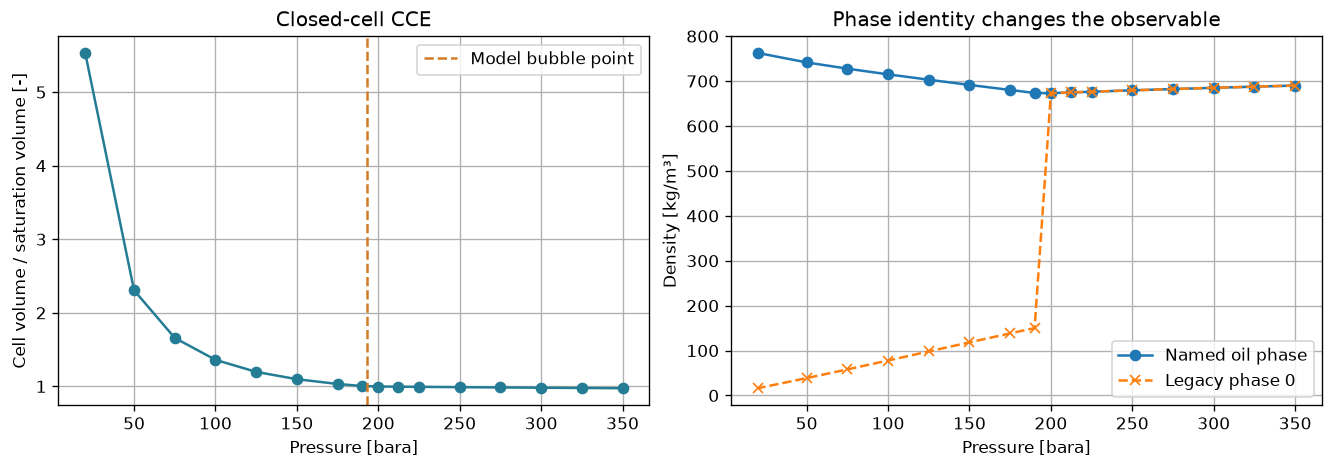

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
axes[0].plot(pressures, cce_results.relative_volume, "o-", color="#247c95")
axes[0].axvline(base_pb, color="#d27b27", linestyle="--", label="Model bubble point")
axes[0].set(
    xlabel="Pressure [bara]",
    ylabel="Cell volume / saturation volume [-]",
    title="Closed-cell CCE",
)
axes[0].legend()
axes[1].plot(pressures, cce_results.oil_density_kg_m3, "o-", label="Named oil phase")
axes[1].plot(pressures, cce_results.legacy_phase0_density_kg_m3, "x--", label="Legacy phase 0")
axes[1].set(
    xlabel="Pressure [bara]",
    ylabel="Density [kg/m³]",
    title="Phase identity changes the observable",
)
axes[1].legend()
plt.show()

## 6. Differential liberation: a different material path

Each pressure step flashes the **remaining liquid** and removes all equilibrium gas.
This is not CCE and not constant-volume depletion (CVD). The paper reports DL, so the
automatic issue's suggested CVD class is not used as a substitute.

At each step, component conservation is checked as initial inventory = remaining liquid
+ cumulative removed gas. Standard gas volumes in the native DL API use 288.15 K and
1.01325 bara. The final stock-tank oil volume uses those same reference conditions.

$$B_o=\frac{V_o(P,T)}{V_{o,\mathrm{stock}}}$$

$B_o$ is m³/m³ and is numerically equal to bbl/STB; $R_s$ is remaining dissolved gas at
standard conditions per stock-tank oil volume (Sm³/Sm³). Paper separator/stock-tank
conditions are incompletely specified, so agreement with its Bo/GOR curves is not claimed.

In [9]:
dle_pressures = np.array(
    [350.0, 300.0, 250.0, 220.0, 200.0, 175.0, 150.0, 125.0, 100.0, 75.0, 50.0, 20.0, 1.01325]
)
dle = DifferentialLiberation(base_fluid.clone())
dle.setTemperature(TEMPERATURE_K, "K")
dle.setPressures(DoubleArray(dle_pressures))
dle.runCalc()
dle_results = pd.DataFrame(
    {
        "P_bara": dle_pressures,
        "Bo_m3_m3": list(dle.getBo()),
        "Rs_Sm3_Sm3": list(dle.getRs()),
        "oil_density_kg_m3": list(dle.getOilDensity()),
    }
)
display(dle_results.round(6))
remaining = base_fluid.clone()
removed = np.zeros_like(initial_inventory)
audit_rows = []
for pressure in dle_pressures:
    state = flash_state(remaining, pressure)
    if state.hasPhaseType("gas"):
        gas = state.getPhase("gas")
        removed += np.array(
            [
                gas.getComponent(index).getNumberOfMolesInPhase()
                for index in range(state.getNumberOfComponents())
            ]
        )
        remaining = state.phaseToSystem("oil")
    else:
        remaining = state
    residual = inventory(remaining) + removed - initial_inventory
    audit_rows.append(
        {
            "P_bara": pressure,
            "remaining_mol": inventory(remaining).sum(),
            "removed_mol": removed.sum(),
            "max_component_residual_mol": float(np.max(np.abs(residual))),
        }
    )
dle_audit = pd.DataFrame(audit_rows)
display(dle_audit.round(9))
checks["DLE_component_ledger"] = float(dle_audit.max_component_residual_mol.max()) < 1e-7
checks["DLE_positive_Bo"] = bool((dle_results.Bo_m3_m3 > 0).all())
checks["DLE_Rs_nonnegative"] = bool((dle_results.Rs_Sm3_Sm3 >= -1e-8).all())
checks["DLE_Rs_decreases"] = bool(np.all(np.diff(dle_results.Rs_Sm3_Sm3) <= 1e-6))
checks["DLE_liquid_inventory_decreases"] = bool(
    np.all(np.diff(dle_audit.remaining_mol) <= 1e-8)
)

,P_bara,Bo_m3_m3,Rs_Sm3_Sm3,oil_density_kg_m3
0,350.00000,1.405597,142.140999,690.120854
1,300.00000,1.415973,142.140999,685.063693
2,250.00000,1.427670,142.140999,679.450897
3,220.00000,1.435450,142.140999,675.768467
4,200.00000,1.441005,142.140999,673.163172
5,175.00000,1.408770,128.280361,680.270761
6,150.00000,1.364053,110.298857,691.469421
7,125.00000,1.321772,93.464636,702.827206
8,100.00000,1.281358,77.580397,714.418247
9,75.00000,1.242153,62.441007,726.346056


,P_bara,remaining_mol,removed_mol,max_component_residual_mol
0,350.00000,100.000010,0.000000,0.0
1,300.00000,100.000010,0.000000,0.0
2,250.00000,100.000010,0.000000,0.0
3,220.00000,100.000010,0.000000,0.0
4,200.00000,100.000010,0.000000,0.0
5,175.00000,94.064917,5.935093,0.0
6,150.00000,86.328292,13.671718,0.0
7,125.00000,79.048671,20.951339,0.0
8,100.00000,72.144169,27.855841,0.0
9,75.00000,65.529132,34.470878,0.0


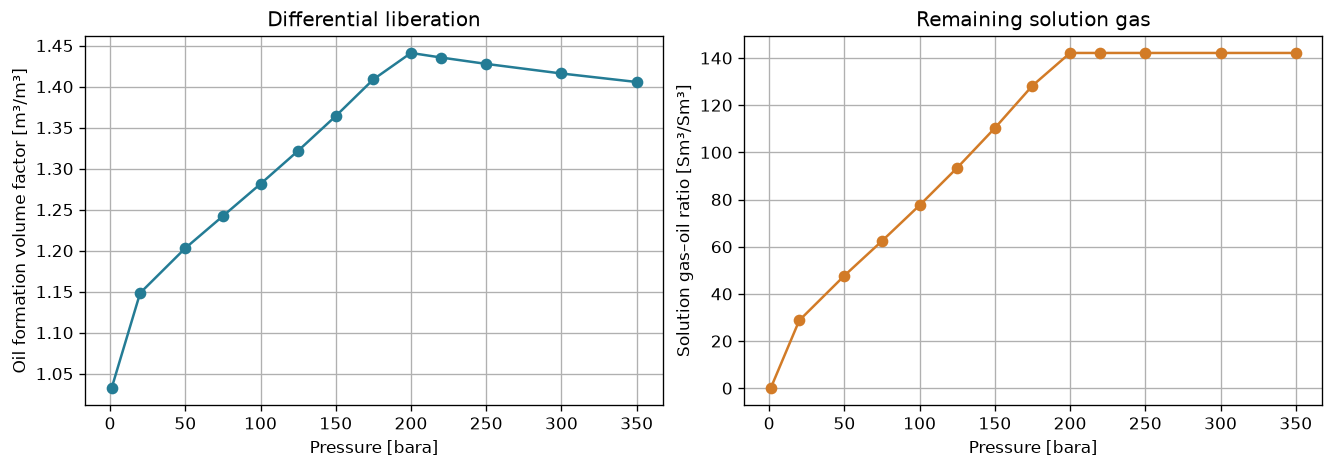

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
axes[0].plot(dle_pressures, dle_results.Bo_m3_m3, "o-", color="#247c95")
axes[0].set(
    xlabel="Pressure [bara]",
    ylabel="Oil formation volume factor [m³/m³]",
    title="Differential liberation",
)
axes[1].plot(dle_pressures, dle_results.Rs_Sm3_Sm3, "o-", color="#d27b27")
axes[1].set(
    xlabel="Pressure [bara]",
    ylabel="Solution gas–oil ratio [Sm³/Sm³]",
    title="Remaining solution gas",
)
plt.show()

## 7. Viscosity and the critical-pressure interpretation

NeqSim supports both its default PFCT transport calculation and the paper's LBC model.
Selecting LBC does not reproduce the authors' unknown critical-volume/viscosity tuning.
This is a fixed-composition CCE transport sensitivity, not a DL-viscosity curve: below
bubble point a differential liquid has a different composition.

,P_bara,PFCT_cP,LBC_cP
0,350.0,0.480846,0.364087
1,250.0,0.437067,0.316380
2,200.0,0.413544,0.291857
3,150.0,0.513050,0.351937
4,100.0,0.658852,0.459458
5,50.0,0.979050,0.649098
6,20.0,1.305710,0.890165


,Table_3_Pc_interpretation,bubble_pressure_bara,relative_error_percent
0,psig,193.100039,-9.009770
1,psia,179.177290,-15.570277


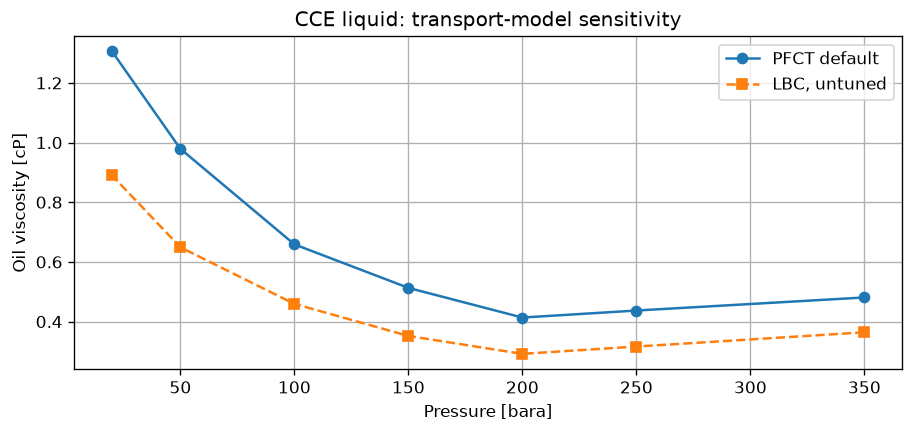

In [11]:
viscosity_rows = []
for pressure in [350.0, 250.0, 200.0, 150.0, 100.0, 50.0, 20.0]:
    default_state = flash_state(base_fluid, pressure)
    lbc_state = flash_state(base_fluid, pressure, "LBC")
    viscosity_rows.append(
        {
            "P_bara": pressure,
            "PFCT_cP": default_state.getPhase("oil").getViscosity("cP"),
            "LBC_cP": lbc_state.getPhase("oil").getViscosity("cP"),
        }
    )
viscosity_results = pd.DataFrame(viscosity_rows)
display(viscosity_results.round(6))
pressure_basis_rows = []
for basis in ["psig", "psia"]:
    model = build_fluid(basis)
    bubble_pressure = saturation_pressure(model)
    pressure_basis_rows.append(
        {
            "Table_3_Pc_interpretation": basis,
            "bubble_pressure_bara": bubble_pressure,
            "relative_error_percent": 100 * (bubble_pressure / PAPER_PB_BARA - 1),
        }
    )
display(pd.DataFrame(pressure_basis_rows).round(6))
checks["positive_finite_viscosities"] = bool(
    np.isfinite(viscosity_results[["PFCT_cP", "LBC_cP"]].to_numpy()).all()
    and (viscosity_results[["PFCT_cP", "LBC_cP"]] > 0).all().all()
)
fig, ax = plt.subplots(figsize=(7.5, 3.5), layout="constrained")
ax.plot(viscosity_results.P_bara, viscosity_results.PFCT_cP, "o-", label="PFCT default")
ax.plot(viscosity_results.P_bara, viscosity_results.LBC_cP, "s--", label="LBC, untuned")
ax.set(
    xlabel="Pressure [bara]",
    ylabel="Oil viscosity [cP]",
    title="CCE liquid: transport-model sensitivity",
)
ax.legend()
plt.show()

## 8. One-observable calibration and independent comparisons

Fit one global multiplier on the six pseudo-component critical temperatures to the
reported saturation pressure. A teaching interval of 0.90–1.15 is declared before fitting;
it is not an approved physical uncertainty range. This is an identifiability exercise,
not the paper's multi-parameter regression. The density and viscosity anchors are held
out and evaluated at the **reported** saturation pressure without further tuning.

$$\mathrm{RE}=100\left(\frac{y_{\mathrm{model}}}{y_{\mathrm{reference}}}-1\right)$$

RE is signed relative error in percent. Do not call a single-point error the paper's
multi-pressure AAE. No curve is digitized or manufactured from the abstract's error claims.

In [12]:
def pressure_residual(multiplier):
    return saturation_pressure(build_fluid(tc_multiplier=multiplier)) - PAPER_PB_BARA


fitted_multiplier = brentq(pressure_residual, 0.90, 1.15, xtol=2e-6)
fitted_fluid = build_fluid(tc_multiplier=fitted_multiplier)
fitted_pb = saturation_pressure(fitted_fluid)
comparison_rows = []
for label, fluid, bubble_pressure in [
    ("Untuned Table 3", base_fluid, base_pb),
    ("Pb-only Tc fit", fitted_fluid, fitted_pb),
]:
    state = flash_state(fluid, PAPER_PB_BARA)
    oil = state.getPhase("oil")
    for quantity, predicted, reference, role in [
        ("Bubble pressure [bara]", bubble_pressure, PAPER_PB_BARA, "calibration"),
        ("Oil density [kg/m³]", oil.getDensity("kg/m3"), 729.7, "hold-out, unit interpreted"),
        ("Oil viscosity [cP]", oil.getViscosity("cP"), 0.776, "hold-out, PFCT model"),
    ]:
        comparison_rows.append(
            {
                "model": label,
                "quantity": quantity,
                "role": role,
                "prediction": predicted,
                "paper_anchor": reference,
                "relative_error_percent": 100 * (predicted / reference - 1),
            }
        )
comparison = pd.DataFrame(comparison_rows)
display(comparison.round(6))
print(f"Fitted heavy-component Tc multiplier: {fitted_multiplier:.7f}")
checks["single_target_fit_residual"] = abs(fitted_pb - PAPER_PB_BARA) < 0.002
print(
    "Hold-out errors remain visible: fitting saturation pressure alone does not qualify the fluid."
)

Fitted heavy-component Tc multiplier: 1.0731084
Hold-out errors remain visible: fitting saturation pressure alone does not qualify the fluid.


,model,quantity,role,prediction,paper_anchor,relative_error_percent
0,Untuned Table 3,Bubble pressure [bara],calibration,193.100039,212.220629,-9.009770
1,Untuned Table 3,Oil density [kg/m³],"hold-out, unit interpreted",674.770171,729.700000,-7.527728
2,Untuned Table 3,Oil viscosity [cP],"hold-out, PFCT model",0.419407,0.776000,-45.952768
3,Pb-only Tc fit,Bubble pressure [bara],calibration,212.220627,212.220629,-0.000001
4,Pb-only Tc fit,Oil density [kg/m³],"hold-out, unit interpreted",650.508360,729.700000,-10.852630
5,Pb-only Tc fit,Oil viscosity [cP],"hold-out, PFCT model",0.491069,0.776000,-36.717917


## 9. Validation, outputs and upstream follow-up

The numerical gates below test algorithmic consistency, phase identity, material
conservation and qualitative pressure trends. Published saturation/density/viscosity
anchors provide a limited external comparison; the paper's full accuracy claims remain
unverified. CCE's independent volume check uses separate state flashes with the same EOS,
so it is a path/API cross-check rather than independent thermodynamic validation.

Three actionable gaps are tracked:

- [#4547 — named CCE oil properties](https://github.com/equinor/neqsim/issues/4547):
  implemented in [draft PR #4556](https://github.com/equinor/neqsim/pull/4556); existing phase-0 getters retain their basis.
- [#4548 — general PR Ωb overrides](https://github.com/equinor/neqsim/issues/4548):
  reusable parameter persistence, default preservation and export semantics need qualification.
- [#4549 — Pedersen first-moment drift](https://github.com/equinor/neqsim/issues/4549):
  retain the observed mass defect and exclude those characterization cases from accepted results.

The parent [#4528](https://github.com/equinor/neqsim/issues/4528) retains the benchmark
qualification work: resolve Table 2 and pressure/density conventions, obtain numerical
CCE/DL observations and uncertainties, supply BIPs/volume shifts/LBC parameters, then fit
bounded identifiable parameters and validate held-out experiments. Do not close it merely
because the notebook executes.

In [13]:
validation = pd.DataFrame(
    [{"check": name, "passed": bool(passed)} for name, passed in checks.items()]
)
display(validation)
assert validation.passed.all(), validation.loc[~validation.passed].to_dict("records")
print(f"Passed {len(validation)} numerical and input checks.")
print(
    "Known Pedersen characterization limitation: diagnostic only. "
    "It is excluded from the passing material-balance gates."
)

output_dir = Path("low_gor_pvt_results")
output_dir.mkdir(exist_ok=True)
for name, frame in {
    "published_light": light,
    "published_lumps": lumps,
    "characterization_diagnostics": characterization,
    "cce": cce_results,
    "dle": dle_results,
    "dle_material_audit": dle_audit,
    "viscosity": viscosity_results,
    "paper_anchor_comparison": comparison,
    "validation": validation,
}.items():
    frame.to_csv(output_dir / f"{name}.csv", index=False)
manifest_out = {
    "runtime": runtime,
    "paper_doi": "10.31699/IJCPE.2026.1.9",
    "paper_license": "CC BY 4.0",
    "temperature_K": TEMPERATURE_K,
    "base_bubble_pressure_bara": base_pb,
    "fitted_Tc_multiplier": fitted_multiplier,
    "upstream_issues": [4528, 4547, 4548, 4549],
    "status": "CAPABILITY_STUDY; FULL_PAPER_BENCHMARK_NOT_QUALIFIED",
}
(output_dir / "manifest.json").write_text(json.dumps(manifest_out, indent=2) + "\n")
with zipfile.ZipFile("low_gor_pvt_results.zip", "w", zipfile.ZIP_DEFLATED) as archive:
    for item in sorted(output_dir.iterdir()):
        archive.write(item, item.name)
print(
    "Saved CSV tables and runtime manifest in low_gor_pvt_results.zip. "
    "Key results are embedded above."
)

Passed 14 numerical and input checks.
Known Pedersen characterization limitation: diagnostic only. It is excluded from the passing material-balance gates.
Saved CSV tables and runtime manifest in low_gor_pvt_results.zip. Key results are embedded above.


,check,passed
0,composition_rounding_under_1e-4_mol_percent,True
1,C7_plus_lump_total,True
2,six_lump_component_count,True
3,Whitson_Gamma_mass_and_moles,True
4,CCE_component_inventory,True
5,CCE_independent_volume,True
6,CCE_positive_compressibility_trend,True
7,DLE_component_ledger,True
8,DLE_positive_Bo,True
9,DLE_Rs_nonnegative,True


## Conclusions and exercises

The existing NeqSim models already cover the central characterization, CCE, differential
liberation and LBC workflow. The published six-lump slate is executable. Default settings
and a saturation-only fit do not establish the authors' multi-property accuracy.

The material-path checks distinguish closed-cell CCE from gas-removing DL; the named
oil-phase reads avoid comparing gas density with laboratory oil density. The Pedersen
diagnostic demonstrates why characterization moments need checks before tuning.

After resolving #4549, try 12/28-lump Pedersen models with a common material basis; compare convergence and
runtime without changing acceptance criteria. Then obtain a numerical laboratory dataset,
reserve a complete experiment for validation, and compare residual structure before
adding regression parameters. Add separator tests only after their pressure, temperature
and standard-volume conventions are supplied.

For a broader lab-to-simulator workflow, see the repository's
[PVT workflow guide](https://equinor.github.io/neqsim/pvtsimulation/pvt_workflow.html)
and its existing Colab examples. This notebook contains no proprietary field data.